In [1]:
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_predict
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score

sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 30)

### Get data

In [6]:
url = "https://fantasy.premierleague.com/api/bootstrap-static/"

data = requests.get(url).json()

data.keys()

dict_keys(['chips', 'events', 'game_settings', 'game_config', 'phases', 'teams', 'total_players', 'element_stats', 'element_types', 'elements'])

In [10]:
players = pd.DataFrame(data['elements'])
teams = pd.DataFrame(data['teams'])
positions = pd.DataFrame(data['element_types'])

players.shape

(672, 109)

## Data Understanding

In [17]:
players.head()

,can_transact,can_select,chance_of_playing_next_round,chance_of_playing_this_round,code,cost_change_event,cost_change_event_fall,cost_change_start,cost_change_start_fall,price_change_percent,price_change_hourly_rate,price_change_projections,price_change_locked_until,price_change_calibrating,dreamteam_count,...,expected_assists_per_90,expected_goal_involvements_per_90,expected_goals_conceded_per_90,goals_conceded_per_90,now_cost_rank,now_cost_rank_type,form_rank,form_rank_type,points_per_game_rank,points_per_game_rank_type,selected_rank,selected_rank_type,starts_per_90,clean_sheets_per_90,defensive_contribution_per_90
0,True,True,NaN,NaN,154561,0,0,2,-2,88.6,90,"[{'offset': 0, 'projected_percent': '89.0', 'l...",None,False,2,...,0.00,0.00,0.76,0.50,52,1,13,1,14,1,6,1,1.00,0.70,0.00
1,True,True,NaN,NaN,109745,0,0,-1,1,-88.4,-1,"[{'offset': 0, 'projected_percent': '-89.3', '...",None,False,0,...,0.00,0.00,0.00,0.00,323,14,562,71,603,72,457,55,0.00,0.00,0.00
2,True,True,NaN,NaN,437495,0,0,-1,1,-82.7,0,"[{'offset': 0, 'projected_percent': '-82.7', '...",None,False,0,...,0.00,0.00,0.00,0.00,341,17,570,73,606,73,549,64,0.00,0.00,0.00
3,True,True,NaN,NaN,226597,1,-1,1,-1,16.6,222,"[{'offset': 0, 'projected_percent': '17.0', 'l...",None,False,1,...,0.02,0.17,0.76,0.50,8,1,2,2,7,3,12,3,1.00,0.70,9.10
4,True,True,100.0,100.0,445122,0,0,0,0,44.3,39,"[{'offset': 0, 'projected_percent': '44.5', 'l...",None,False,0,...,0.15,0.16,1.09,0.81,42,2,126,50,245,90,177,70,0.81,0.54,4.84


In [21]:
players.columns.to_list()

['can_transact',
 'can_select',
 'chance_of_playing_next_round',
 'chance_of_playing_this_round',
 'code',
 'cost_change_event',
 'cost_change_event_fall',
 'cost_change_start',
 'cost_change_start_fall',
 'price_change_percent',
 'price_change_hourly_rate',
 'price_change_projections',
 'price_change_locked_until',
 'price_change_calibrating',
 'dreamteam_count',
 'element_type',
 'ep_next',
 'ep_this',
 'event_points',
 'first_name',
 'form',
 'id',
 'in_dreamteam',
 'news',
 'news_added',
 'now_cost',
 'photo',
 'points_per_game',
 'removed',
 'second_name',
 'selected_by_percent',
 'special',
 'squad_number',
 'status',
 'team',
 'team_code',
 'total_points',
 'transfers_in',
 'transfers_in_event',
 'transfers_out',
 'transfers_out_event',
 'value_form',
 'value_season',
 'web_name',
 'known_name',
 'region',
 'team_join_date',
 'birth_date',
 'has_temporary_code',
 'opta_code',
 'minutes',
 'goals_scored',
 'assists',
 'clean_sheets',
 'goals_conceded',
 'own_goals',
 'penalties_s

In [19]:
columns = [
    "web_name", "team", "element_type", "now_cost", "status",
    "minutes", "starts",
    "goals_scored", "assists", "clean_sheets",
    "expected_goals", "expected_assists", "expected_goals_conceded",
    "defensive_contribution", "selected_by_percent",
    "total_points",
]

df = players[columns].copy()

df.head()

,web_name,team,element_type,now_cost,status,minutes,starts,goals_scored,assists,clean_sheets,expected_goals,expected_assists,expected_goals_conceded,defensive_contribution,selected_by_percent,total_points
0,Raya,1,1,62,a,900,10,0,0,7,0.00,0.01,7.59,0,47.5,60
1,Arrizabalaga,1,1,49,a,0,0,0,0,0,0.00,0.00,0.00,0,0.1,0
2,Meslier,1,1,49,a,0,0,0,0,0,0.00,0.00,0.00,0,0.0,0
3,Gabriel,1,2,81,a,900,10,1,0,7,1.47,0.25,7.59,91,26.1,66
4,J.Timber,1,2,65,a,335,3,0,0,2,0.02,0.57,4.06,18,1.0,14


In [23]:
df.dtypes

web_name                   object
team                        int64
element_type                int64
now_cost                    int64
status                     object
minutes                     int64
starts                      int64
goals_scored                int64
assists                     int64
clean_sheets                int64
expected_goals             object
expected_assists           object
expected_goals_conceded    object
defensive_contribution      int64
selected_by_percent        object
total_points                int64
dtype: object

In [29]:
teams.head()

,code,draw,form,id,loss,name,played,points,position,short_name,strength,team_division,unavailable,win,link_url,strength_overall_home,strength_overall_away,strength_attack_home,strength_attack_away,strength_defence_home,strength_defence_away,pulse_id
0,3,0,None,1,0,Arsenal,0,0,1,ARS,None,None,False,0,,4,5,0,0,0,0,1
1,7,0,None,2,0,Aston Villa,0,0,10,AVL,None,None,False,0,,3,3,0,0,0,0,2
2,91,0,None,3,0,Bournemouth,0,0,7,BOU,None,None,False,0,,3,4,0,0,0,0,127
3,94,0,None,4,0,Brentford,0,0,8,BRE,None,None,False,0,,3,4,0,0,0,0,130
4,36,0,None,5,0,Brighton,0,0,2,BHA,None,None,False,0,,4,4,0,0,0,0,131


In [27]:
positions.head()

,id,plural_name,plural_name_short,singular_name,singular_name_short,squad_select,squad_min_select,squad_max_select,squad_min_play,squad_max_play,ui_shirt_specific,sub_positions_locked,element_count
0,1,Goalkeepers,GKP,Goalkeeper,GKP,2,None,None,1,1,True,[12],75
1,2,Defenders,DEF,Defender,DEF,5,None,None,3,5,False,[],219
2,3,Midfielders,MID,Midfielder,MID,5,None,None,2,5,False,[],299
3,4,Forwards,FWD,Forward,FWD,3,None,None,1,3,False,[],79


In [31]:
df["team"] = df["team"].map(teams.set_index("id")["name"])
df["position"] = df["element_type"].map(positions.set_index("id")["singular_name_short"])
df["price"] = df["now_cost"] / 10

text_numbers = ["expected_goals", "expected_assists", "expected_goals_conceded", "selected_by_percent"]
df[text_numbers] = df[text_numbers].apply(pd.to_numeric)

df = df.drop(columns=["element_type", "now_cost"])
df.head()

,web_name,team,status,minutes,starts,goals_scored,assists,clean_sheets,expected_goals,expected_assists,expected_goals_conceded,defensive_contribution,selected_by_percent,total_points,position,price
0,Raya,Arsenal,a,900,10,0,0,7,0.00,0.01,7.59,0,47.5,60,GKP,6.2
1,Arrizabalaga,Arsenal,a,0,0,0,0,0,0.00,0.00,0.00,0,0.1,0,GKP,4.9
2,Meslier,Arsenal,a,0,0,0,0,0,0.00,0.00,0.00,0,0.0,0,GKP,4.9
3,Gabriel,Arsenal,a,900,10,1,0,7,1.47,0.25,7.59,91,26.1,66,DEF,8.1
4,J.Timber,Arsenal,a,335,3,0,0,2,0.02,0.57,4.06,18,1.0,14,DEF,6.5


In [38]:
df.shape

(672, 16)

In [35]:
# missing values

df.isnull().sum().sum()

0

A player who has played 20 minutes all season tells us nothing. We keep only players with at least **270 minutes** (three full matches).

- Change the minutes filter from 270 to 450. Do the results change?
- Add "clean_sheets" to the features. Does the MAE get better?
- Find the best value goalkeeper under £5m.

In [78]:
df = df[df["minutes"] >= 450].reset_index(drop=True)
df.shape

(208, 19)

## Explore the data

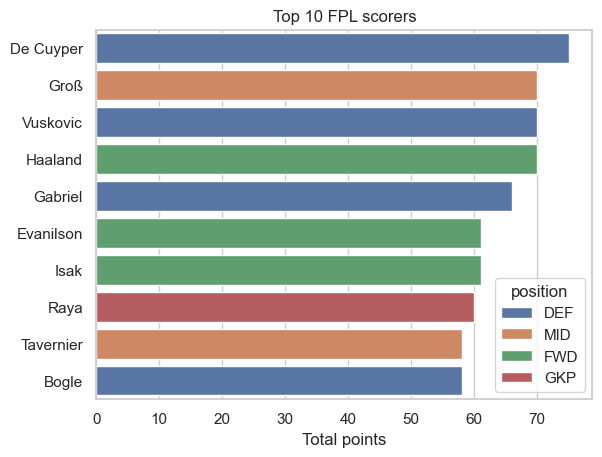

In [80]:
top10 = df.nlargest(10, "total_points")

sns.barplot(data=top10, x="total_points", y="web_name", hue="position", dodge=False)
plt.title("Top 10 FPL scorers")
plt.xlabel("Total points")
plt.ylabel("")
plt.show()

## Do expensive players score?

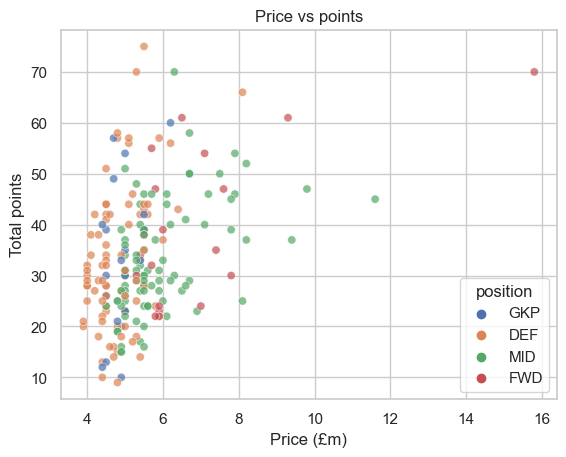

In [82]:
sns.scatterplot(data=df, x="price", y="total_points", hue="position", alpha=0.7)
plt.title("Price vs points")
plt.xlabel("Price (£m)")
plt.ylabel("Total points")
plt.show()

Mostly yes, but look at the spread. Plenty of cheap players outscore expensive ones. That's where value lives.

**Expected goals vs real goals**

Expected goals (xG) measures the quality of a player's chances. A player above the line is finishing better than expected. A player below it is missing chances, or getting unlucky.

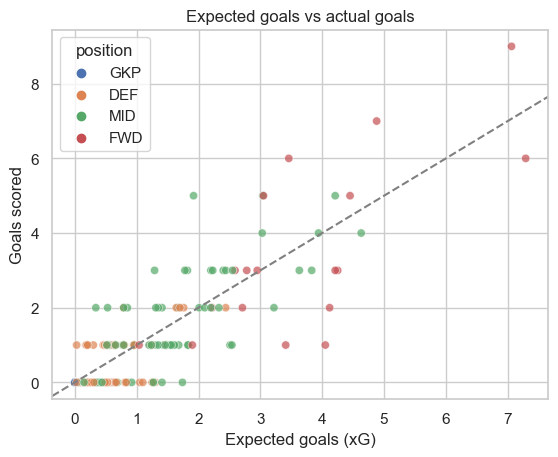

In [85]:
sns.scatterplot(data=df, x="expected_goals", y="goals_scored", hue="position", alpha=0.7)
plt.axline((0, 0), slope=1, color="grey", linestyle="--")
plt.title("Expected goals vs actual goals")
plt.xlabel("Expected goals (xG)")
plt.ylabel("Goals scored")
plt.show()

## Which position scored the most?

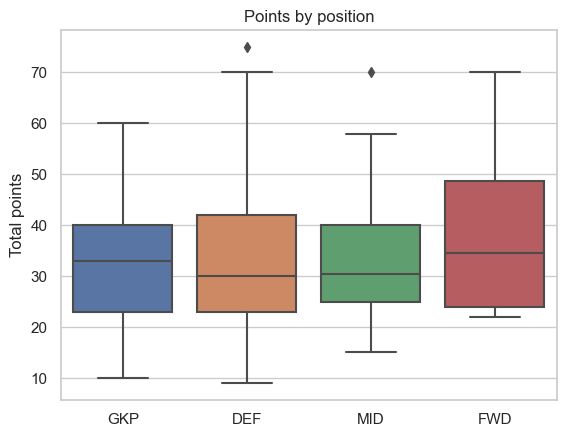

In [88]:
sns.boxplot(data=df, x="position", y="total_points", order=["GKP", "DEF", "MID", "FWD"])
plt.title("Points by position")
plt.xlabel("")
plt.ylabel("Total points")
plt.show()

## Build the model

In [91]:
features = [
    "minutes", "starts", "price", "clean_sheets",
    "expected_goals", "expected_assists", "expected_goals_conceded",
    "defensive_contribution",
]

X = pd.get_dummies(df[features + ["position"]], columns=["position"], dtype=int)
y = df["total_points"]

X.head()

,minutes,starts,price,clean_sheets,expected_goals,expected_assists,expected_goals_conceded,defensive_contribution,position_DEF,position_FWD,position_GKP,position_MID
0,900,10,6.2,7,0.00,0.01,7.59,0,0,0,1,0
1,900,10,8.1,7,1.47,0.25,7.59,91,1,0,0,0
2,767,9,5.9,6,1.22,1.01,6.93,42,1,0,0,0
3,532,7,5.4,4,0.18,0.83,2.84,28,1,0,0,0
4,596,7,9.4,4,3.63,1.20,5.10,46,0,0,0,1


In [93]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

len(X_train), len(X_test)

(166, 42)

In [95]:
linear = LinearRegression().fit(X_train, y_train)
forest = RandomForestRegressor(n_estimators=300, random_state=42).fit(X_train, y_train)

### Evaluate the models

In [98]:
baseline = [y_train.mean()] * len(y_test)

results = pd.DataFrame({
    "MAE": [
        mean_absolute_error(y_test, baseline),
        mean_absolute_error(y_test, linear.predict(X_test)),
        mean_absolute_error(y_test, forest.predict(X_test)),
    ],
    "R²": [
        r2_score(y_test, baseline),
        r2_score(y_test, linear.predict(X_test)),
        r2_score(y_test, forest.predict(X_test)),
    ],
}, index=["Guess the average", "Linear regression", "Random forest"]).round(2)

results

,MAE,R²
Guess the average,9.78,-0.01
Linear regression,5.75,0.68
Random forest,6.48,0.51


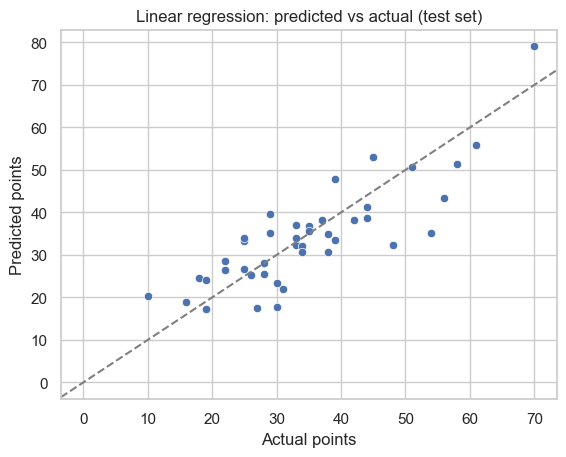

In [100]:
best_name = results["MAE"].iloc[1:].idxmin()
best_model = {"Linear regression": linear, "Random forest": forest}[best_name]

sns.scatterplot(x=y_test, y=best_model.predict(X_test))
plt.axline((0, 0), slope=1, color="grey", linestyle="--")
plt.title(f"{best_name}: predicted vs actual (test set)")
plt.xlabel("Actual points")
plt.ylabel("Predicted points")
plt.show()

## The Features that contributed most to the Random Forest model?

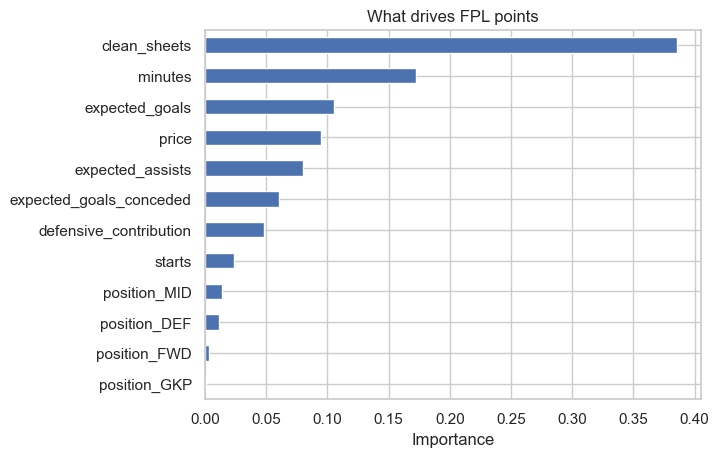

In [103]:
importance = pd.Series(forest.feature_importances_, index=X.columns).sort_values()

importance.plot(kind="barh")
plt.title("What drives FPL points")
plt.xlabel("Importance")
plt.show()

## Use the model

In [106]:
df["expected_points"] = cross_val_predict(best_model, X, y, cv=5).round(1)
df["luck"] = (df["total_points"] - df["expected_points"]).round(1)

show = ["web_name", "team", "position", "price", "total_points", "expected_points", "luck", "selected_by_percent"]

In [108]:
df.nsmallest(10, "luck")[show]

,web_name,team,position,price,total_points,expected_points,luck,selected_by_percent
97,Gonzalo,Fulham,FWD,5.9,24,54.3,-30.3,3.6
94,Bobb,Fulham,MID,5.5,35,53.7,-18.7,0.5
37,Thiago,Brentford,FWD,7.8,30,48.1,-18.1,8.1
4,Saka,Arsenal,MID,9.4,37,50.8,-13.8,5.5
69,Henderson,Crystal Palace,GKP,4.9,10,23.3,-13.3,1.0
143,Barcola,Liverpool,MID,8.1,25,38.2,-13.2,4.4
70,Benitez,Crystal Palace,GKP,4.5,13,25.3,-12.3,0.1
172,Wissa,Newcastle,FWD,5.9,22,34.2,-12.2,8.3
96,King,Fulham,MID,5.5,39,50.6,-11.6,3.3
144,Enzo,Man City,MID,6.9,23,34.4,-11.4,3.6


In [110]:
df["value"] = (df["expected_points"] / df["price"]).round(1)

(df[df["status"] == "a"]
   .sort_values("value", ascending=False)
   .groupby("position")
   .head(3)
   .sort_values(["position", "value"], ascending=[True, False])
   [show + ["value"]])

,web_name,team,position,price,total_points,expected_points,luck,selected_by_percent,value
41,Boscagli,Brighton,DEF,4.5,44,47.1,-3.1,0.7,10.5
121,Bogle,Leeds,DEF,4.8,58,49.9,8.1,11.2,10.4
42,De Cuyper,Brighton,DEF,5.5,75,56.6,18.4,47.8,10.3
88,Barry,Everton,FWD,5.7,55,61.2,-6.2,10.7,10.7
97,Gonzalo,Fulham,FWD,5.9,24,54.3,-30.3,3.6,9.2
129,Calvert-Lewin,Leeds,FWD,6.0,39,49.7,-10.7,17.6,8.3
39,Verbruggen,Brighton,GKP,4.7,57,47.9,9.1,24.0,10.2
189,Kinsky,Spurs,GKP,4.4,40,38.2,1.8,15.6,8.7
0,Raya,Arsenal,GKP,6.2,60,49.2,10.8,47.5,7.9
94,Bobb,Fulham,MID,5.5,35,53.7,-18.7,0.5,9.8


### Find the best value goalkeeper under £5m.

In [116]:
df["value"] = (df["clean_sheets"] / df["price"]).round(1)

best_gk = (
    df[(df["status"] == "a") & (df["position"] == "GKP") & (df["price"] < 5.0)]
    .sort_values("value", ascending=False)
    [show + ["value"]]
)

best_gk.head(5)

,web_name,team,position,price,total_points,expected_points,luck,selected_by_percent,value
39,Verbruggen,Brighton,GKP,4.7,57,47.9,9.1,24.0,1.5
189,Kinsky,Spurs,GKP,4.4,40,38.2,1.8,15.6,0.9
20,Petrović,Bournemouth,GKP,4.5,30,33.5,-3.5,3.2,0.7
89,Leno,Fulham,GKP,4.5,39,34.3,4.7,4.4,0.7
107,Tzolakis,Hull City,GKP,4.7,49,34.8,14.2,13.5,0.6
